# 03 — Analyse exploratoire

**Objectif** : caractériser le volume de ventes par plage de prix, par région
et dans le temps.

Questions guides :

1. Comment les ventes se répartissent-elles entre les trois plages de prix ?
2. Le volume québécois suit-il une tendance ou un cycle ?
3. La part des ventes de plus de 500 000 $ progresse-t-elle ?
4. Quelles régions portent le marché, et où le haut de gamme est-il dominant ?
5. Observe-t-on une saisonnalité mensuelle ?

Chaque figure est enregistrée dans `outputs/figures/`.

In [ ]:
import importlib
import sys
from pathlib import Path

racine = Path.cwd().resolve()
if not (racine / "src").is_dir():
    racine = racine.parent
sys.path.insert(0, str(racine))

import src

importlib.reload(src)


import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

from src import FIGURES_DIR, VENTES_PROPRES_CSV

sns.set_theme(style="whitegrid")
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

ORDRE_PLAGES = [
    "Moins de 250 000 $",
    "De 250 000 $ à 500 000 $",
    "Plus de 500 000 $",
]


def enregistrer(nom):
    plt.tight_layout()
    plt.savefig(FIGURES_DIR / f"{nom}.png", dpi=150, bbox_inches="tight")

In [3]:
df = pd.read_csv(
    VENTES_PROPRES_CSV,
    parse_dates=["periode"],
    dtype={"id_region": str, "code_plage_prix": str, "code_nature_acte": str},
)
df["plage_prix"] = pd.Categorical(df["plage_prix"], categories=ORDRE_PLAGES, ordered=True)
df.head()

,periode,id_region,code_plage_prix,code_nature_acte,nombre_ventes,region,plage_prix,nature_acte
0,2021-01-01,1,1,1,240,Bas-Saint-Laurent,Moins de 250 000 $,Vente
1,2021-01-01,1,2,1,29,Bas-Saint-Laurent,De 250 000 $ à 500 000 $,Vente
2,2021-01-01,1,3,1,6,Bas-Saint-Laurent,Plus de 500 000 $,Vente
3,2021-01-01,2,1,1,298,Saguenay–Lac-Saint-Jean,Moins de 250 000 $,Vente
4,2021-01-01,2,2,1,48,Saguenay–Lac-Saint-Jean,De 250 000 $ à 500 000 $,Vente


## 1. Répartition des ventes par plage de prix

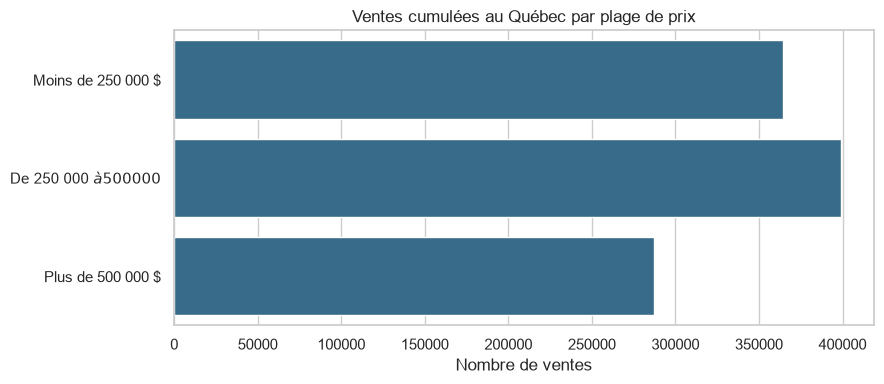

,plage_prix,nombre_ventes,part_pct
0,Moins de 250 000 $,364135,34.671698
1,De 250 000 $ à 500 000 $,398901,37.981998
2,Plus de 500 000 $,287201,27.346304


In [4]:
par_plage = (
    df.groupby("plage_prix", observed=True, as_index=False)["nombre_ventes"]
    .sum()
)
par_plage["part_pct"] = 100 * par_plage["nombre_ventes"] / par_plage["nombre_ventes"].sum()

plt.figure(figsize=(9, 4))
sns.barplot(data=par_plage, x="nombre_ventes", y="plage_prix", color="#2a6f97")
plt.title("Ventes cumulées au Québec par plage de prix")
plt.xlabel("Nombre de ventes")
plt.ylabel("")
enregistrer("03_ventes_par_plage")
plt.show()

par_plage

## 2. Évolution du volume total et par plage

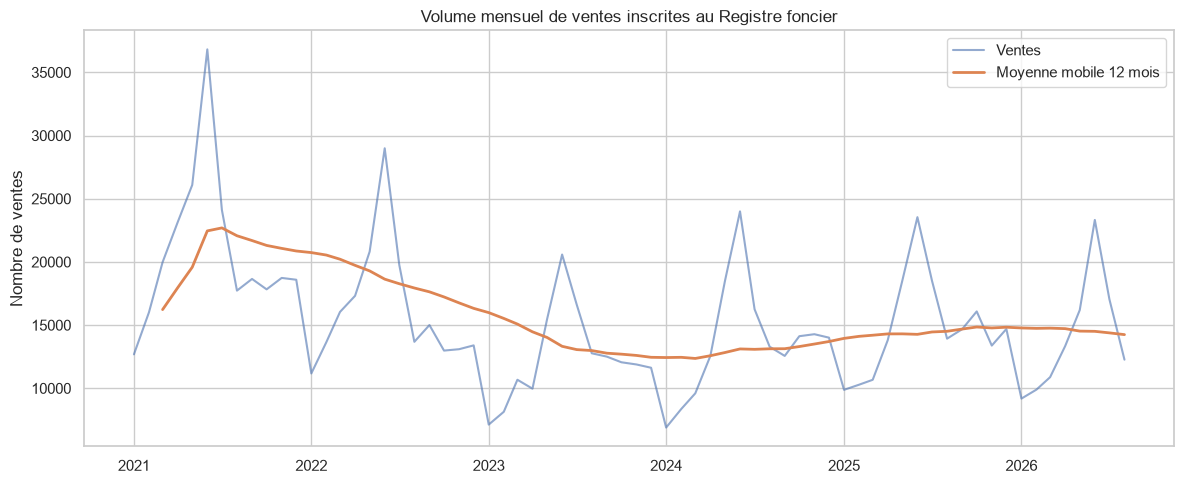

In [5]:
total = df.groupby("periode", as_index=False)["nombre_ventes"].sum()
total["moyenne_mobile_12"] = total["nombre_ventes"].rolling(12, min_periods=3).mean()

plt.figure(figsize=(12, 5))
plt.plot(total["periode"], total["nombre_ventes"], label="Ventes", alpha=0.6)
plt.plot(total["periode"], total["moyenne_mobile_12"], label="Moyenne mobile 12 mois", linewidth=2)
plt.title("Volume mensuel de ventes inscrites au Registre foncier")
plt.ylabel("Nombre de ventes")
plt.legend()
enregistrer("03_evolution_volume_total")
plt.show()

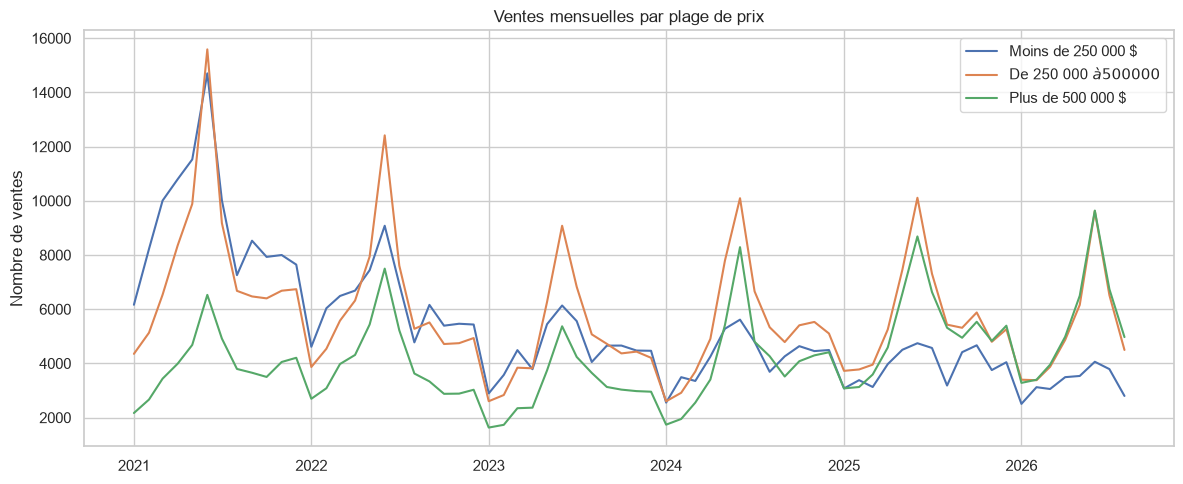

In [6]:
par_mois_plage = (
    df.groupby(["periode", "plage_prix"], observed=True, as_index=False)["nombre_ventes"]
    .sum()
)

plt.figure(figsize=(12, 5))
sns.lineplot(data=par_mois_plage, x="periode", y="nombre_ventes", hue="plage_prix")
plt.title("Ventes mensuelles par plage de prix")
plt.ylabel("Nombre de ventes")
plt.xlabel("")
plt.legend(title="")
enregistrer("03_evolution_par_plage")
plt.show()

## 3. Glissement des parts de marché

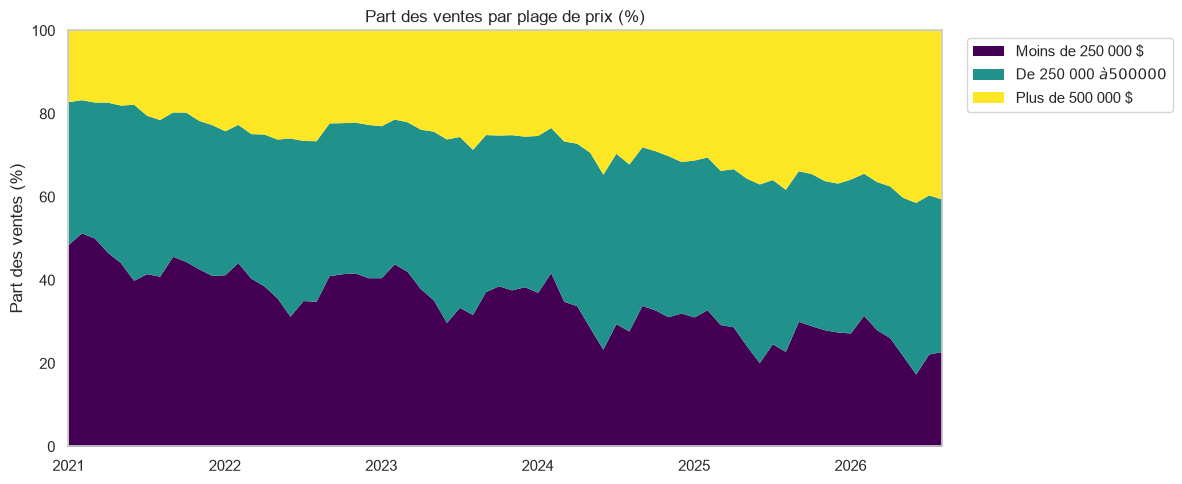

In [7]:
pivot = par_mois_plage.pivot(index="periode", columns="plage_prix", values="nombre_ventes").fillna(0)
parts = pivot.div(pivot.sum(axis=1), axis=0) * 100

fig, ax = plt.subplots(figsize=(12, 5))
parts.plot.area(ax=ax, colormap="viridis", linewidth=0)
ax.set_title("Part des ventes par plage de prix (%)")
ax.set_ylabel("Part des ventes (%)")
ax.set_xlabel("")
ax.set_ylim(0, 100)
ax.legend(title="", bbox_to_anchor=(1.02, 1), loc="upper left")
enregistrer("03_parts_de_marche")
plt.show()

## 4. Géographie du marché

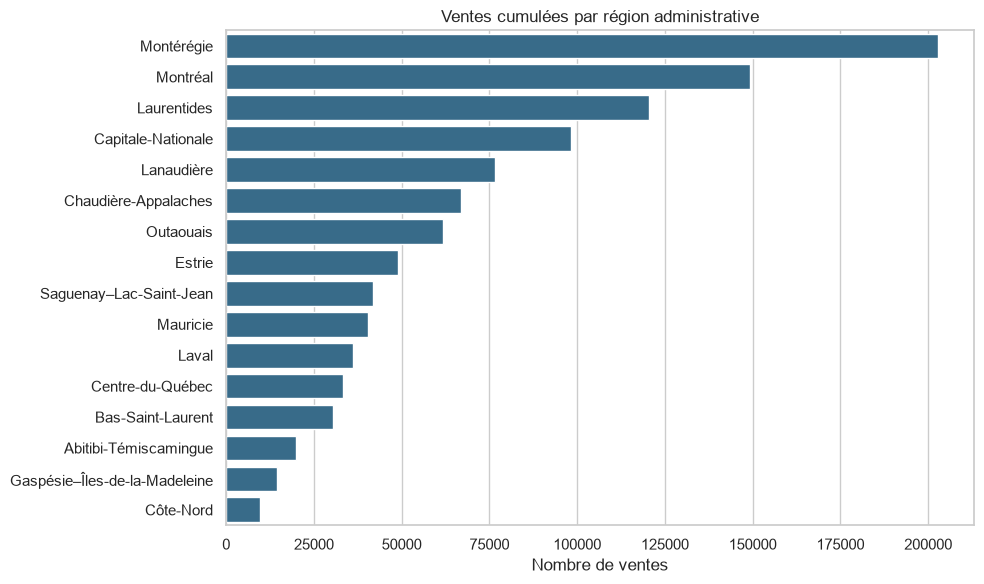

,id_region,region,nombre_ventes
14,16,Montérégie,202908
5,6,Montréal,149127
13,15,Laurentides,120332
2,3,Capitale-Nationale,98350
12,14,Lanaudière,76644
10,12,Chaudière-Appalaches,66763
6,7,Outaouais,61629
4,5,Estrie,48924
1,2,Saguenay–Lac-Saint-Jean,41700
3,4,Mauricie,40262


In [8]:
par_region = (
    df.groupby(["id_region", "region"], as_index=False)["nombre_ventes"]
    .sum()
    .sort_values("nombre_ventes", ascending=False)
)

plt.figure(figsize=(10, 6))
sns.barplot(data=par_region, x="nombre_ventes", y="region", color="#2a6f97")
plt.title("Ventes cumulées par région administrative")
plt.xlabel("Nombre de ventes")
plt.ylabel("")
enregistrer("03_ventes_par_region")
plt.show()

par_region

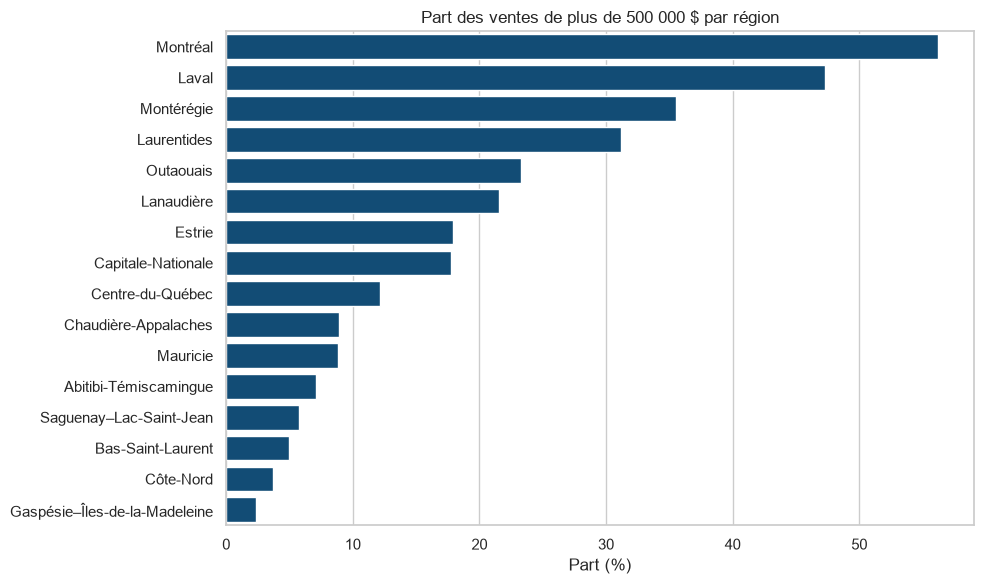

In [11]:
part_haute = (
    df.assign(haute=df["plage_prix"].eq("Plus de 500 000 $") * df["nombre_ventes"])
    .groupby("region", as_index=False)
    .agg(ventes=("nombre_ventes", "sum"), haute=("haute", "sum"))
)
part_haute["part_plus_500k"] = 100 * part_haute["haute"] / part_haute["ventes"]
part_haute = part_haute.sort_values("part_plus_500k", ascending=False)

plt.figure(figsize=(10, 6))
sns.barplot(data=part_haute, x="part_plus_500k", y="region", color="#014f86")
plt.title("Part des ventes de plus de 500 000 $ par région")
plt.xlabel("Part (%)")
plt.ylabel("")
enregistrer("03_part_haut_de_gamme_region")
plt.show()

## 5. Saisonnalité mensuelle

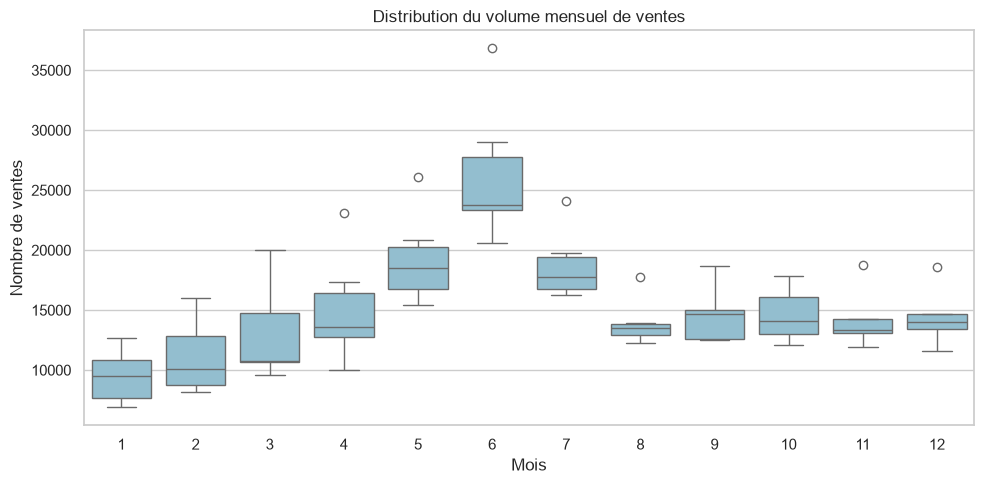

In [12]:
total["mois"] = total["periode"].dt.month

plt.figure(figsize=(10, 5))
sns.boxplot(data=total, x="mois", y="nombre_ventes", color="#89c2d9")
plt.title("Distribution du volume mensuel de ventes")
plt.xlabel("Mois")
plt.ylabel("Nombre de ventes")
enregistrer("03_saisonnalite_mensuelle")
plt.show()

## Synthèse

À compléter après exécution :

- Plage dominante : …
- Tendance du volume total : …
- Glissement vers le haut de gamme : …
- Régions les plus actives : …
- Mois les plus actifs : …
- Hypothèses à tester dans le notebook `04` : …